# hw2: Решающие деревья

*Спасибо великому курсу великого Евгения Соколова*

Автор: Богданов Михаил

### О задании

Задание состоит из двух разделов:
1. В первом разделе вы научитесь применять деревья из sklearn для задачи классификации. Вы посмотрите какие разделяющие поверхности деревья строят для различных датасетов и проанализируете их зависимость от различных гиперпараметров.
2. Во втором разделе вы попробуете реализовать свое решающее дерево и сравните его со стандартное имплементацией из sklearn. Вы также протестируете деревья на более сложных датасетах и сравните различные подходы к кодированию категориальных признаков.

Все данные, на которых будут обучаться модели, вы можете найти на диске.

### Оценивание и штрафы
Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). Максимально допустимая оценка за работу — 10 баллов. Неэффективная и/или неоригинальная реализация кода может негативно отразиться на оценке.

### Формат сдачи
Заполненный ноутбук ```hw2-trees.ipynb``` и модуль с реализованными функциями и классами ```hw2code.py``` необходимо загрузить на свой Github. Затем нужно оставить комментарий в Google-таблице с оценками в столбце `hw2` в строке со своей фамилией о том, что вы выполнили работу с указанием ника на Kaggle.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

from hw2code import DecisionTree, find_best_split

SEED = 42
data = Path('data')

# 1. Решающие деревья. Визуализация.

In [2]:
from sklearn.datasets import make_moons, make_circles, make_classification
datasets = [
    make_circles(noise=0.2, factor=0.5, random_state=42),
    make_moons(noise=0.2, random_state=42),
    make_classification(n_classes=3, n_clusters_per_class=1, n_features=2, class_sep=.8, random_state=3,
                        n_redundant=0, )
]

__Задание 1. (1 балл)__

Для каждого датасета обучите решающее дерево с параметрами по умолчанию, предварительно разбив выборку на обучающую и тестовую. Постройте разделящие поверхности (для этого воспользуйтесь функцией `plot_surface`, пример ниже). Посчитайте accuracy на обучающей и тестовой выборках. Сильно ли деревья переобучились?

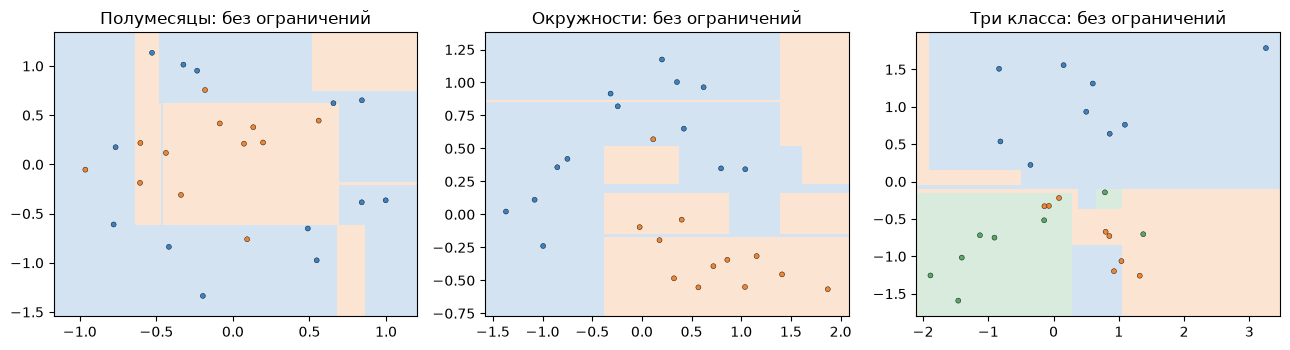

,Данные,Настройки,Train accuracy,Test accuracy
0,Полумесяцы,без ограничений,1.0,0.80
1,Окружности,без ограничений,1.0,0.96
2,Три класса,без ограничений,1.0,0.76


In [3]:
names = ['Полумесяцы', 'Окружности', 'Три класса']
splits = [train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
          for X, y in datasets]
cmap = ListedColormap(['#3b82c4', '#ed8533', '#55a868'])

def plot_surface(ax, model, X, y):
    lo, hi = X.min(axis=0) - 0.2, X.max(axis=0) + 0.2
    xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], 180), np.linspace(lo[1], hi[1], 180))
    labels = model.predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.pcolormesh(xx, yy, labels, cmap=cmap, vmin=0, vmax=2, alpha=0.22, shading='auto')
    ax.scatter(*X.T, c=y, cmap=cmap, vmin=0, vmax=2, s=13, edgecolors='k', linewidths=0.3)

def run_surfaces(settings, *, error=False):
    fig, axes = plt.subplots(len(settings), 3, figsize=(13, 3.6 * len(settings)), squeeze=False)
    rows = []
    for (label, params), axes_row in zip(settings, axes):
        for name, (X_tr, X_te, y_tr, y_te), ax in zip(names, splits, axes_row):
            model = DecisionTreeClassifier(random_state=SEED, **params).fit(X_tr, y_tr)
            train, test = model.score(X_tr, y_tr), model.score(X_te, y_te)
            rows.append((name, label, 1 - train if error else train, 1 - test if error else test))
            plot_surface(ax, model, X_te, y_te)
            ax.set_title(f'{name}: {label}')
    fig.tight_layout()
    plt.show()
    suffix = 'error' if error else 'accuracy'
    display(pd.DataFrame(rows, columns=['Данные', 'Настройки', f'Train {suffix}', f'Test {suffix}']).round(4))

run_surfaces([('без ограничений', {})])

**Ответ 1.** На обучении получили accuracy 1,00 у всех трёх деревьев. На тесте — 0,80 на полумесяцах, 0,96 на окружностях и 0,76 на трёх классах. На полумесяцах и трёх классах видим заметное переобучение, на окружностях разрыв меньше.

__Задание 2. (1.5 балла)__

Попробуйте перебрать несколько параметров для регуляризации (напр. `max_depth`, `min_samples_leaf`). Для каждого набора гиперпараметров постройте разделяющую поверхность, выведите обучающую и тестовую ошибки. Можно делать кросс-валидацию или просто разбиение на трейн и тест, главное делайте каждый раз одинаковое разбиение, чтобы можно было корректно сравнивать (помните же, что итоговое дерево сильно зависит от небольшого изменения обучающей выборки?). Проследите как меняется разделяющая поверхность и обобщающая способность. Почему так происходит, одинаково ли изменение для разных датасетов?

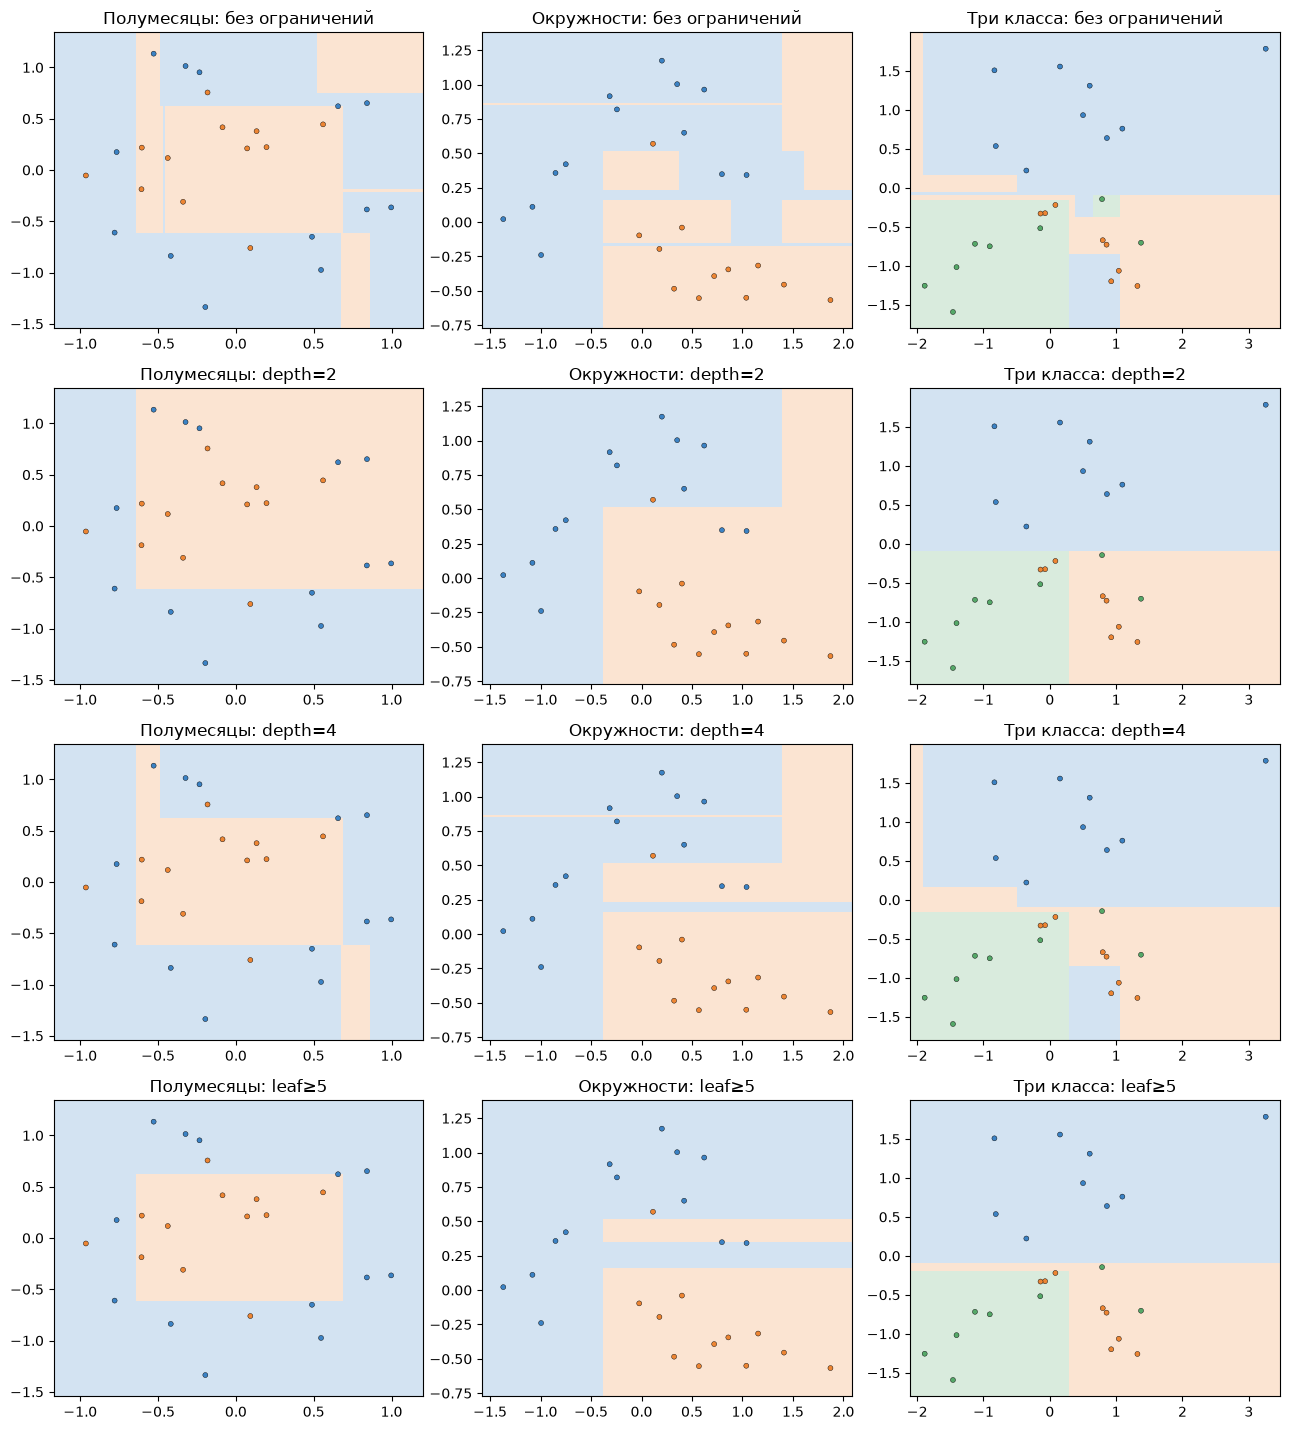

,Данные,Настройки,Train error,Test error
0,Полумесяцы,без ограничений,0.0000,0.20
1,Окружности,без ограничений,0.0000,0.04
2,Три класса,без ограничений,0.0000,0.24
3,Полумесяцы,depth=2,0.2000,0.36
4,Окружности,depth=2,0.0933,0.12
5,Три класса,depth=2,0.1200,0.20
6,Полумесяцы,depth=4,0.0400,0.20
7,Окружности,depth=4,0.0533,0.12
8,Три класса,depth=4,0.0400,0.28
9,Полумесяцы,leaf≥5,0.0667,0.16


In [4]:
run_surfaces([
    ('без ограничений', {}),
    ('depth=2', {'max_depth': 2}),
    ('depth=4', {'max_depth': 4}),
    ('leaf≥5', {'min_samples_leaf': 5}),
], error=True)

**Ответ 2.** Когда ограничиваем глубину, граница становится проще. На полумесяцах при глубине 2 получаем ошибку 0,36 вместо 0,20: двух уровней не хватает, чтобы отделить полумесяцы. Если оставить минимум пять точек в листе, получаем 0,16 на полумесяцах и 0,20 на трёх классах вместо 0,24. На окружностях получаем те же 0,04.

# 2. Решающие деревья своими руками

В этой части вам нужно реализовать свой класс для обучения решающего дерева в задаче бинарной классификации с возможностью обработки вещественных и категориальных признаков.

__Задание 3. (1.5 балл)__

Реализуйте функцию find_best_split из модуля hw2code.py

Реализуем `find_best_split` в `hw2code.py`: сортируем значения и по накопленной сумме считаем классы с обеих сторон каждого порога. Выбираем порог с наибольшим значением критерия. На маленьких примерах проверяем и обычное разбиение, и выбор при равных значениях.

In [5]:
thresholds, ginis, threshold, gini = find_best_split([1, 1, 3, 4], [0, 0, 1, 1])
np.testing.assert_allclose(thresholds, [2, 3.5])
np.testing.assert_allclose(ginis, [0, -1 / 3])
assert threshold == 2 and gini == 0
assert find_best_split([1, 2, 3], [0, 1, 0])[2] == 1.5
assert find_best_split([2, 2], [0, 1])[2] is None
print('Проверки разбиения прошли.')

Проверки разбиения прошли.


__Задание 4. (0.5 балла)__

Загрузите таблицу students.csv (это немного преобразованный датасет [User Knowledge](https://archive.ics.uci.edu/ml/datasets/User+Knowledge+Modeling)). В ней признаки объекта записаны в первых пяти столбцах, а в последнем записана целевая переменная (класс: 0 или 1). Постройте на одном изображении пять кривых "порог — значение критерия Джини" для всех пяти признаков. Отдельно визуализируйте scatter-графики "значение признака — класс" для всех пяти признаков.

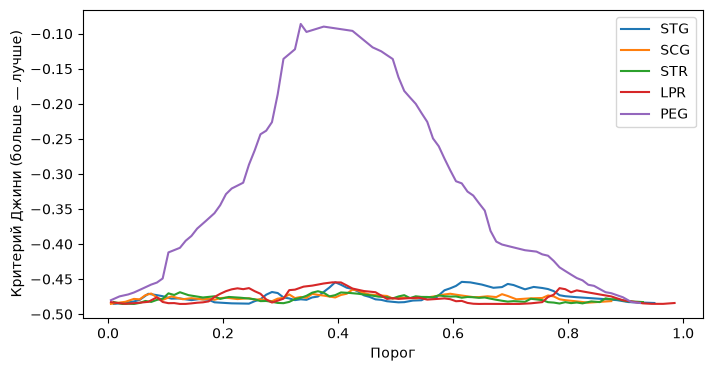

,Признак,Порог,Критерий
4,PEG,0.335,-0.086066
0,STG,0.615,-0.453977
3,LPR,0.390,-0.454668
1,SCG,0.425,-0.465019
2,STR,0.365,-0.467338


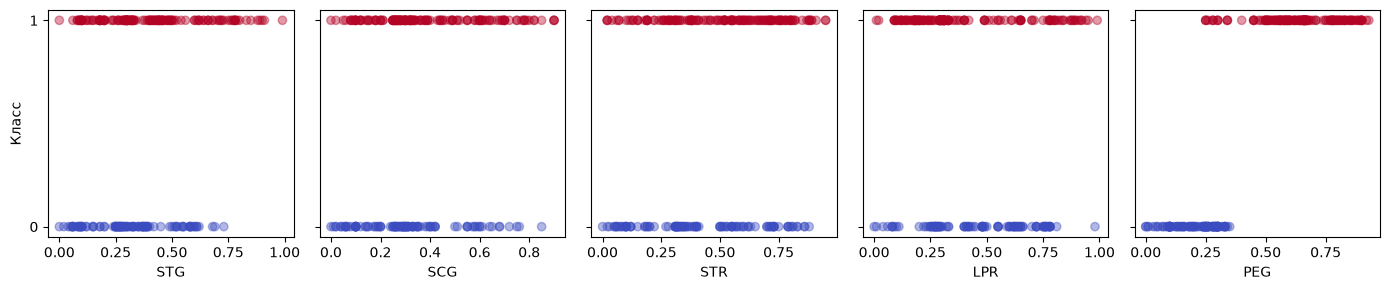

In [6]:
students = pd.read_csv(data / 'students.csv')
target = students.iloc[:, -1].to_numpy()
fig, ax = plt.subplots(figsize=(8, 4))
best = []
for col in students.columns[:-1]:
    thresholds, ginis, threshold, gini = find_best_split(students[col], target)
    ax.plot(thresholds, ginis, label=col)
    best.append((col, threshold, gini))
ax.set(xlabel='Порог', ylabel='Критерий Джини (больше — лучше)')
ax.legend()
plt.show()
display(pd.DataFrame(best, columns=['Признак', 'Порог', 'Критерий']).sort_values('Критерий', ascending=False))

fig, axes = plt.subplots(1, 5, figsize=(14, 3), sharey=True)
for col, ax in zip(students.columns[:-1], axes):
    ax.scatter(students[col], target, c=target, cmap='coolwarm', alpha=0.4)
    ax.set(xlabel=col, yticks=[0, 1])
axes[0].set_ylabel('Класс')
fig.tight_layout()
plt.show()

__Задание 5. (0.5 балла)__

Исходя из кривых значений критерия Джини, по какому признаку нужно производить деление выборки на два поддерева? Согласуется ли этот результат с визуальной оценкой scatter-графиков? Как бы охарактеризовали вид кривой для "хороших" признаков, по которым выборка делится почти идеально? Чем отличаются кривые для признаков, по которым деление практически невозможно?

**Ответ 5.** Выбираем `PEG`: при пороге 0,335 получаем критерий −0,086, у второго признака — около −0,454. На графике `PEG` тоже видим самое явное разделение. Если по обе стороны порога почти чистые группы, получаем значение близко к нулю. Если классы перемешаны при любом пороге, получаем более низкую и пологую кривую.

__Задание 6. (1.5 балла).__

Разберитесь с уже написанным кодом в классе DecisionTree модуля hw2code.py. Найдите ошибки в реализации метода \_fit_node. Напишите функцию \_predict_node.

 Построение дерева осуществляется согласно базовому жадному алгоритму, предложенному в лекции. Выбор лучшего разбиения необходимо производить по критерию Джини. Критерий останова: все объекты в листе относятся к одному классу или ни по одному признаку нельзя разбить выборку. Ответ в листе: наиболее часто встречающийся класс в листе. Для категориальных признаков выполняется преобразование, описанное в лекции в разделе «Учет категориальных признаков».

В `_fit_node` проверяем, одинаковы ли все метки, и перебираем признаки с нулевого столбца. Категории упорядочиваем по доле положительного класса. Каждому потомку передаём только его строки и их метки. Если дошли до листа, возвращаем класс большинства.

In [7]:
toy = np.array([[0, 2], [1, 2], [2, 2], [3, 2]])
labels = np.array([0, 0, 1, 1])
tree = DecisionTree(['real', 'real']).fit(toy, labels)
np.testing.assert_array_equal(tree.predict(toy), labels)
categories = np.array([['a'], ['b'], ['c'], ['d']])
tree = DecisionTree(['categorical']).fit(categories, labels)
np.testing.assert_array_equal(tree.predict(categories), labels)
assert DecisionTree(['real', 'real'], min_samples_leaf=3).fit(toy, labels)._tree['type'] == 'terminal'
assert DecisionTree(['real', 'real'], min_samples_split=5).fit(toy, labels)._tree['type'] == 'terminal'
print('Проверки дерева прошли.')

Проверки дерева прошли.


__Задание 7. (0.5 балла)__

Протестируйте свое решающее дерево на датасете [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom). Вам нужно скачать таблицу agaricus-lepiota.data (лежит на гитхабе вместе с заданием), прочитать ее с помощью pandas, применить к каждому столбцу LabelEncoder (из sklearn), чтобы преобразовать строковые имена категорий в натуральные числа. Первый столбец — это целевая переменная (e — edible, p — poisonous) Мы будем измерять качество с помощью accuracy, так что нам не очень важно, что будет классом 1, а что — классом 0. Обучите решающее дерево на половине случайно выбранных объектов (признаки в датасете категориальные) и сделайте предсказания для оставшейся половины. Вычислите accuracy.

У вас должно получиться значение accuracy, равное единице (или очень близкое к единице), и не очень глубокое дерево.

In [8]:
def encode(frame):
    return np.column_stack([LabelEncoder().fit_transform(frame[col]) for col in frame.columns])

def depth(node):
    if node['type'] == 'terminal':
        return 0
    return 1 + max(depth(node['left_child']), depth(node['right_child']))

mushrooms = pd.read_csv(data / 'agaricus-lepiota.data', header=None)
X_mushrooms = encode(mushrooms.iloc[:, 1:])
y_mushrooms = LabelEncoder().fit_transform(mushrooms.iloc[:, 0])
X_tr, X_te, y_tr, y_te = train_test_split(X_mushrooms, y_mushrooms, test_size=0.5,
                                          random_state=SEED, stratify=y_mushrooms)
tree = DecisionTree(['categorical'] * X_tr.shape[1]).fit(X_tr, y_tr)
print(f'Accuracy на грибах: {accuracy_score(y_te, tree.predict(X_te)):.4f}; глубина: {depth(tree._tree)}')

Accuracy на грибах: 1.0000; глубина: 7


__Задание 8. (бонус, 1 балл)__

Реализуйте в классе DecisionTree поддержку параметров max_depth, min_samples_split и min_samples_leaf по аналогии с DecisionTreeClassifier. Постройте графики зависимости качества предсказания в зависимости от этих параметров для набора данных tic-tac-toe (см. следующий пункт).

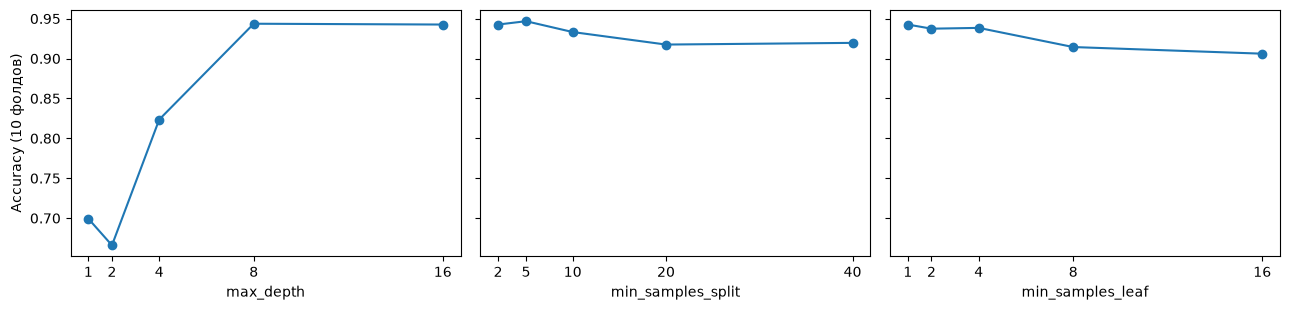

In [9]:
tic = pd.read_csv(data / 'tic-tac-toe-endgame.csv')
X_tic = encode(tic.iloc[:, :-1])
y_tic = LabelEncoder().fit_transform(tic.iloc[:, -1])
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
tic_types = ['categorical'] * X_tic.shape[1]
parameters = {'max_depth': [1, 2, 4, 8, 16], 'min_samples_split': [2, 5, 10, 20, 40],
              'min_samples_leaf': [1, 2, 4, 8, 16]}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for (param, values), ax in zip(parameters.items(), axes):
    scores = [cross_val_score(DecisionTree(tic_types, **{param: val}), X_tic, y_tic,
                              scoring='accuracy', cv=cv).mean() for val in values]
    ax.plot(values, scores, marker='o')
    ax.set(xlabel=param, xticks=values)
axes[0].set_ylabel('Accuracy (10 фолдов)')
fig.tight_layout()
plt.show()

__Задание 9. (2 балла)__

Загрузите следующие наборы данных (напомним, что pandas умеет загружать файлы по url, в нашем случае это файл \*.data), предварительно ознакомившись с описанием признаков и целевой переменной в каждом из них (она записаны в Data Folder, в файле *.names): 
* [mushrooms](https://archive.ics.uci.edu/ml/datasets/Mushroom) (загрузили в предыдущем пункте, классы записаны в нулевом столбце)
* [tic-tac-toe](https://archive.ics.uci.edu/ml/datasets/Tic-Tac-Toe+Endgame) (классы записаны в последнем столбце, датасет лежит на гитхабе вместе с заданием)
* [cars](https://archive.ics.uci.edu/ml/datasets/Car+Evaluation) (классы записаны в последнем столбце, считаем что unacc, acc — это класс 0, good, vgood — класс 1)
* [nursery](https://archive.ics.uci.edu/ml/datasets/Nursery) (классы записаны в последнем столбце, считаем, что not_recom и recommend — класс 0, very_recom, priority, spec_prior — класс 1).

Закодируйте категориальные признаки, использовав LabelEncoder. С помощью cross_val_score (cv=10) оцените accuracy на каждом из этих наборов данных следующих алгоритмов:
* DecisionTree, считающий все признаки вещественными
* DecisionTree, считающий все признаки категориальными
* DecisionTree, считающий все признаки вещественными + one-hot-encoding всех признаков
* DecisionTreeClassifier из sklearn. Запишите результат в pd.DataFrame (по строкам — наборы данных, по столбцам — алгоритмы).

Рекомендации:
* Чтобы cross_val_score вычисляла точность, нужно передать scoring=make_scorer(accuracy_score), обе фукнции из sklearn.metrics.
* Если вам позволяет память (а она скорее всего позволяет), указывайте параметр sparse=False в OneHotEncoder (если вы, конечно, используете его). Иначе вам придется добиваться того, чтобы ваша реализация дерева умела работать с разреженными матрицами (что тоже, в целом, не очень сложно).

In [10]:
from sklearn.base import BaseEstimator, ClassifierMixin

class RealTree(ClassifierMixin, BaseEstimator):
    def fit(self, X, y):
        self.tree_ = DecisionTree(['real'] * X.shape[1]).fit(X, y)
        self.classes_ = self.tree_.classes_
        return self

    def predict(self, X):
        return self.tree_.predict(X)

cars = pd.read_csv(data / 'car.data', header=None)
nursery = pd.read_csv(data / 'nursery.data', header=None)
evaluation = {
    'Mushrooms': (X_mushrooms, y_mushrooms),
    'Tic-tac-toe': (X_tic, y_tic),
    'Cars': (encode(cars.iloc[:, :-1]), cars.iloc[:, -1].isin(['good', 'vgood']).to_numpy(dtype=int)),
    'Nursery': (encode(nursery.iloc[:, :-1]), nursery.iloc[:, -1]
                .isin(['very_recom', 'priority', 'spec_prior']).to_numpy(dtype=int)),
}
rows = {}
with threadpool_limits(limits=2):
    for name, (X, y) in evaluation.items():
        methods = {
            'Свое: числовые': RealTree(),
            'Свое: категориальные': DecisionTree(['categorical'] * X.shape[1]),
            'Свое: one-hot': make_pipeline(OneHotEncoder(handle_unknown='ignore', sparse_output=False), RealTree()),
            'sklearn': DecisionTreeClassifier(random_state=SEED),
        }
        rows[name] = {label: cross_val_score(model, X, y, cv=cv, scoring='accuracy',
                                             error_score='raise').mean()
                      for label, model in methods.items()}
display(pd.DataFrame.from_dict(rows, orient='index').round(4))
print('Лидеры:', pd.DataFrame.from_dict(rows, orient='index').idxmax(axis=1).to_dict())

,Свое: числовые,Свое: категориальные,Свое: one-hot,sklearn
Mushrooms,1.0000,1.0000,1.0000,1.0000
Tic-tac-toe,0.8789,0.9426,0.9384,0.8884
Cars,0.9919,0.9919,0.9884,0.9919
Nursery,0.9996,0.9998,0.9998,0.9997


Лидеры: {'Mushrooms': 'Свое: числовые', 'Tic-tac-toe': 'Свое: категориальные', 'Cars': 'Свое: категориальные', 'Nursery': 'Свое: категориальные'}


__Задание 10. (1 балла)__

Проанализируйте результаты эксперимента. 
Одинаково ли для разных наборов данных ранжируются алгоритмы? 
Порассуждайте, почему так происходит. 

Обратите внимание на значение признаков в разных наборах данных. 
Присутствует ли в результатах какая-то компонента случайности? 
Можно ли повлиять на нее и улушить работу алгоритмов?

**Ответ 10.** Одинакового порядка не получили. На грибах у всех accuracy 1,00, а на крестиках-ноликах выигрывают категориальные разбиения (0,9426) и one-hot (0,9384). Числа после `LabelEncoder` ставят символы в условный порядок, которого у них нет. На Cars и Nursery видим небольшую разницу между методами. Для честного сравнения используем одни фолды, а для проверки устойчивости можем повторить расчёт с другим seed. Если подбираем параметры, проверяем качество на отдельных данных.

Вставьте что угодно, описывающее ваши впечатления от этого задания:

На полумесяцах хорошо видим, как дерево глубины 2 упрощает границу и начинает путать классы.